In [1]:
import numpy as np
import pandas as pd
import copy

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import src.CBMD as CBMD
from src.plots import *

# Part 2 : Toroidal models

## Circle (d=1)

### Von mises distribution
$$
f(\theta \mid \mu, \kappa) =  \frac{\exp(\kappa \cos(\theta - \mu))}{2\pi I_0(\kappa}
$$

In [3]:
von_mises = CBMD.Von_mises(np.pi / 2 , 10)

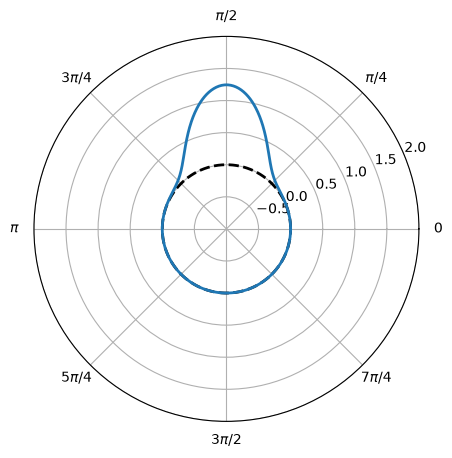

In [4]:
fig, ax = plt.subplots(figsize=(5, 5), subplot_kw={"projection": "polar"})
plot_circular_density(ax, von_mises)

### Wrapped cauchy distribution
$$
f(\theta \mid \mu, \rho) = \frac{1}{2\pi}\frac{1-\rho^2}{1+\rho^2-2\rho\cos(\theta-\mu)}
$$

In [5]:
wrapped_cauchy = CBMD.Wrapped_cauchy(np.pi / 2 , 0.75)

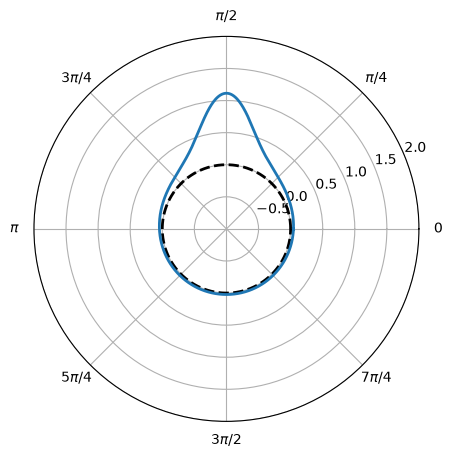

In [6]:
fig, ax = plt.subplots(figsize=(5,5), subplot_kw={"projection": "polar"})
plot_circular_density(ax, wrapped_cauchy)

## 2D Torus (d=2)

In [7]:
resolution = 100
x = np.linspace(-np.pi, np.pi, resolution)
y = np.linspace(-np.pi, np.pi, resolution)

X, Y = np.meshgrid(x, y)
coords_2d = np.column_stack((X.ravel(), Y.ravel()))

### Joint von mises
$$
f(\theta_1, \theta_2) = vM_1(\theta_1) vM_2(\theta_2)
$$

In [8]:
joint_von_mises = CBMD.Joint_von_mises([0, 0] , [5, 5])

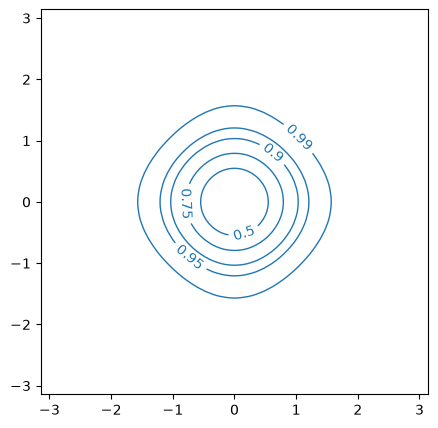

In [9]:
density = joint_von_mises.pdf(coords_2d).reshape(100,100)
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_confidence(ax, density)

### Bivariate von mises (sine variant) : no normalized closed form
$$
f(\theta_1, \theta_2) \propto \exp \left(\kappa_1\cos(\theta_1-\mu_1) + \kappa_2\cos(\theta_2-\mu_2) + \lambda\sin(\theta_1-\mu_1)\sin(\theta_2-\mu_2)\right)
$$

In [10]:
def bivariate_von_mises_unnormalized_pdf(values, mu, kappa, lam):
    return np.exp(kappa[0] * np.cos(values[0] - mu[0]) + 
                  kappa[1] * np.cos(values[1] - mu[1]) + 
                  lam * np.sin(values[0] - mu[0]) * np.sin(values[1] - mu[1]))

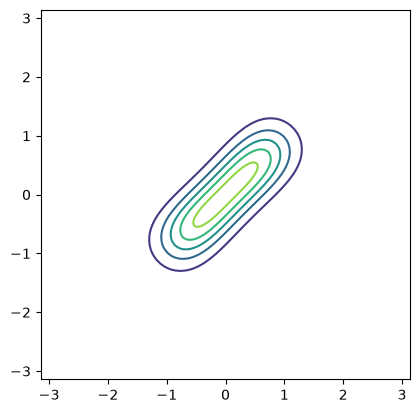

In [11]:
mu = [0,0]
kappa = [5,5]
lam = 5

unnorm_density = np.array([bivariate_von_mises_unnormalized_pdf(coord_2d, mu, kappa, lam) for coord_2d in coords_2d])
unnorm_density = unnorm_density.reshape(100, 100)


plt.xlim(-np.pi, np.pi)
plt.ylim(-np.pi, np.pi)
plt.gca().set_aspect('equal', adjustable='box')
plt.contour(X, Y, unnorm_density, levels=5)


## d-Torus (d>2) : circula based multivariate distribution

### Joint von Mises with wrapped Cauchy circula (vM-wC distribution)
$$
f(\mathbf{\theta}) = f_1(\theta_1) \cdot ... \cdot f_d(\theta_d) \cdot C(F_1(\theta_1), ..., F_d(\theta_d)) 
$$

In [12]:
von_mises_1 = CBMD.Von_mises(0 , 5)
von_mises_2 = CBMD.Von_mises(0 , 5)
von_mises_3 = CBMD.Von_mises(1 , 2)

marginals = [von_mises_1, von_mises_2, von_mises_3]
qs =  [1.0, 1.0, -1.0]
rhos = [0.5, 0.5, 0.3]

vmwc_circula = CBMD.Wrapped_cauchy_CBMD(marginals, qs, rhos)

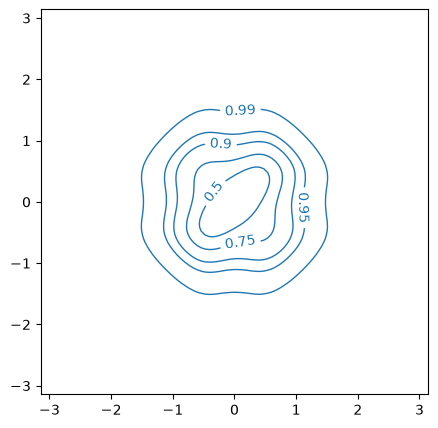

In [13]:
density = vmwc_circula.marginalize([0,1]).pdf(coords_2d).reshape(100,100)
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_confidence(ax, density)

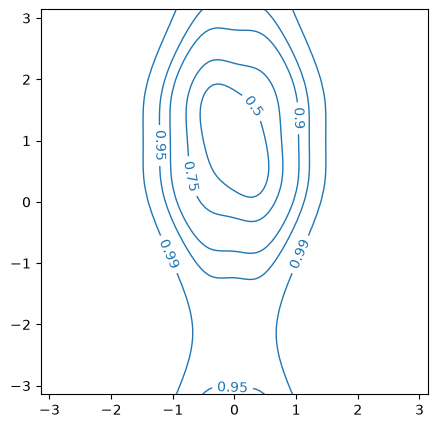

In [14]:
density = vmwc_circula.marginalize([0,2]).pdf(coords_2d).reshape(100,100)
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_confidence(ax, density)

## d-Torus (d>2) : amino acid mixture models

### Load ALA and CYS models

In [15]:
ALA_model = CBMD.Mixture_model.from_file("../models/VMWC_ALA_model.csv", component_type="VMWC")
PRO_model = CBMD.Mixture_model.from_file("../models/VMWC_PRO_model.csv", component_type="VMWC")


### Generate samples

In [16]:
ALA_sample = ALA_model.sample(size=10)
PRO_sample = PRO_model.sample(size=10)

#### Plot ALA

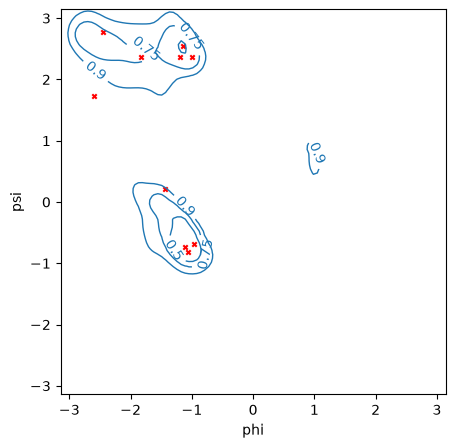

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_single_model(ax, ALA_model, 0, 1, "phi", "psi")
ax.scatter(ALA_sample[:,0], ALA_sample[:,1], s=10, marker='x', color='red')

#### Plot PRO

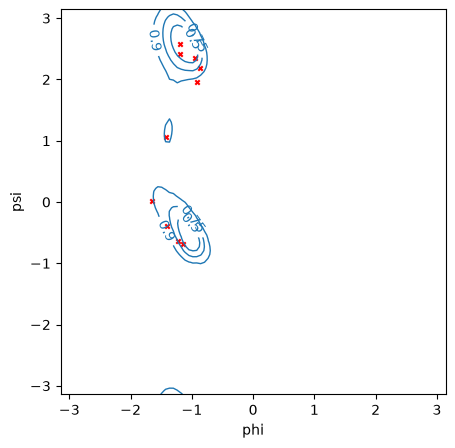

In [18]:
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_single_model(ax, PRO_model, 0, 1, "phi", "psi")
ax.scatter(PRO_sample[:,0], PRO_sample[:,1], s=10, marker='x', color='red')

# Part 3 : Conditioning SERALA model on the capping mechanism

## Default SERALA model

### Load SER-ALA pair model

In [19]:
SERALA_model = CBMD.Mixture_model.from_file("../models/VMWC_SER_ALA_model.csv", component_type="VMWC")

### Generate samples

In [20]:
SERALA_sample = SERALA_model.sample(size=10)

### Plot sample

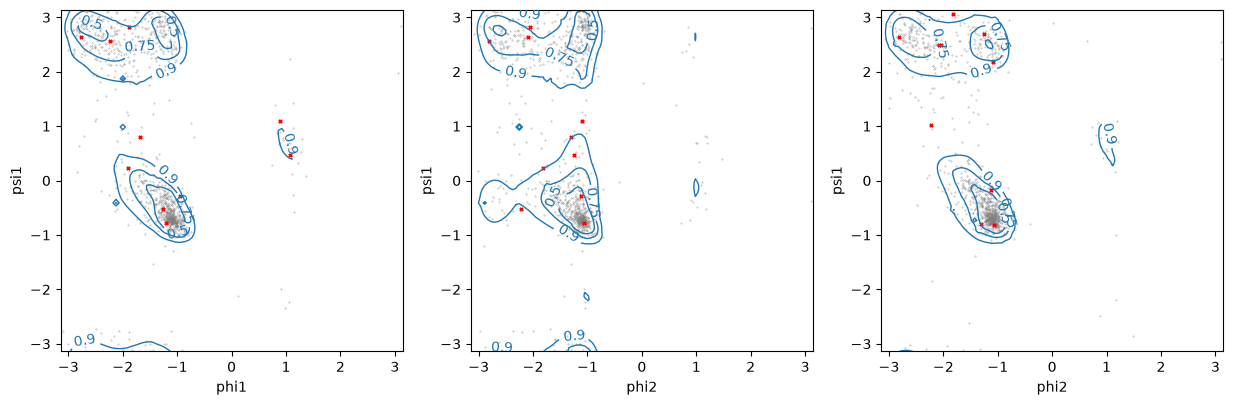

In [7]:
plot_serala_sample(SERALA_model, SERALA_sample)

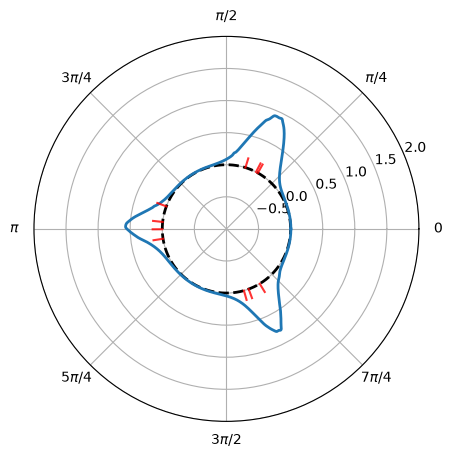

In [58]:
plot_serine_rotamer(SERALA_model, SERALA_sample)

In [21]:
visualize_serala_sample(SERALA_sample, "SERALA_sample", "../src/sbl-pdb-align.py")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## Condition SERALA model using capping data

### Get capping dataset

In [24]:
#Load SERALA observations
SERALA_df = pd.read_csv("../data/SER_ALA_data")
#Select only observation where SER is not Helix and ALA is Helix (transition)
SERALA_helix_transition_df = SERALA_df[(SERALA_df["dssp1"] != 'H') & (SERALA_df["dssp2"] == 'H')]
SERALA_helix_transition_data = SERALA_helix_transition_df.drop(columns=["dssp1", "dssp2"]).to_numpy()

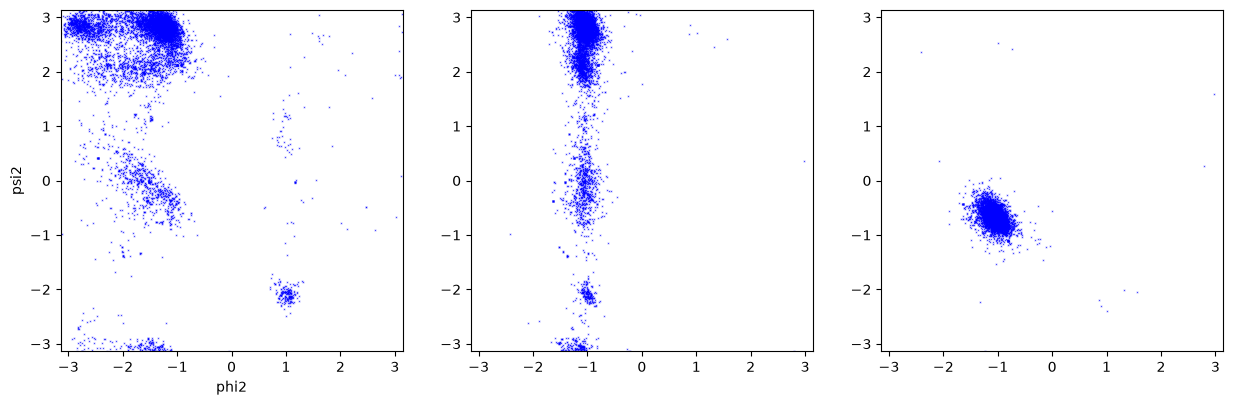

In [25]:
plot_serala_data(SERALA_helix_transition_data)

### Condition SERALA model to capping

In [26]:
def compute_responsibilities(mm, sample):
    resps = np.zeros(shape=(sample.shape[0], len(mm.weights)))

    for i in range(len(mm.weights)):
        weight = mm.weights[i]
        component = mm.components[i]
        resps[:,i] = component.pdf(sample) * weight

    resps_sums = resps.sum(axis=1, keepdims=True)

    resps = resps / resps_sums
        
    return resps

In [27]:
# Compute component responsibility for each datapoint
responsibilities = compute_responsibilities(SERALA_model, SERALA_helix_transition_data)
responsibilities_sum = responsibilities.sum(axis=0)

In [28]:
# Reweight SERALA model using the component responsibilities
SERALA_helix_transition_model = copy.deepcopy(SERALA_model)
SERALA_helix_transition_weights = responsibilities_sum * SERALA_model.weights
SERALA_helix_transition_weights = SERALA_helix_transition_weights / SERALA_helix_transition_weights.sum()
SERALA_helix_transition_model.weights = SERALA_helix_transition_weights

### Generate capping sample

In [29]:
SERALA_helix_transition_sample = SERALA_helix_transition_model.sample(size=10)

### Plot capping sample

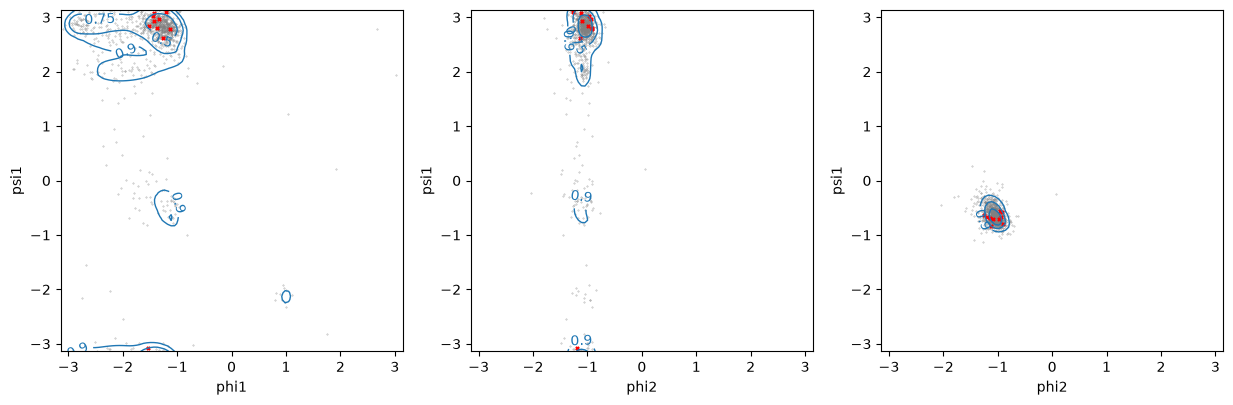

In [56]:
plot_serala_sample(SERALA_helix_transition_model, SERALA_helix_transition_sample)

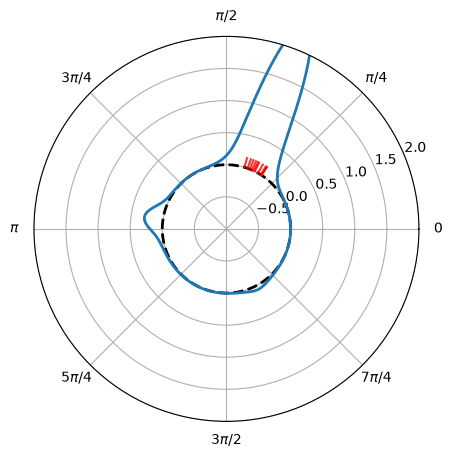

In [57]:
plot_serine_rotamer(SERALA_helix_transition_model, SERALA_helix_transition_sample)

In [30]:
visualize_serala_sample(SERALA_helix_transition_sample, "SERALA_helix_transition_sample", "../src/sbl-pdb-align.py")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.